# Validating the TRENTo+Filter Pipeline: Reweighting, Synchronization & RNG Reproducibility

This notebook performs **TRENTo‑only** tests (no hydro) to:
1. Generate 1 M minimum‑bias events for a few selected design points.
2. Plot the entropy and centrality distributions.
3. Apply the acceptance filter (`P_acc(C)`) and use inverse‑probability weighting to recover the original entropy distribution.
4. Quantify the **synchronization** of the acceptance decision across design points.
5. Discuss **Python RNG reproducibility** across platforms and versions.

The analysis is performed step‑by‑step, with visual diagnostics.

# Cell 1: Imports & Configuration


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import subprocess
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
import seaborn as sns
from scipy.stats import pearsonr, ks_2samp
import os   # <---- ADD THIS LINE
import warnings
warnings.filterwarnings('ignore')

# ------------------------------
# Directories & binary
BASE_DIR       = Path("/home/thiagos/UCC_project/Trento_events")
LHS_DIR        = BASE_DIR / "my_lhs_design_210"
ISO_WORK_DIR   = BASE_DIR / "pbpb_deformed_5.02TeV_new"
TRENTO_BIN     = BASE_DIR / "trento_sync/build/src/trento"
CACHE_DIR      = BASE_DIR / "trento_sync_cache/1M"   # separate cache for this test
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Design points to test (choose a subset for speed)
DESIGN_INDICES = [0, 5, 10, 15, 20]   # 5 design points
EVENTS_PER_DESIGN = 1_000_000         # 1 million events per design
CORES_PER_DESIGN = 60                 # parallel chunks per design (adjust to your machine)
BASE_SEED = 42

# TRENTo fixed parameters (same as in the production script)
TRENTO_FIXED = {
    "cross-section":      "7.0",
    "normalization":      "20.0",
    "reduced-thickness":  "0.0",
    "fluctuation":        "0.19",
    "nucleon-min-dist":   "0.81",
}

# Load design matrix
design_data = np.load(LHS_DIR / "lhs_design_matrix.npz")
X           = design_data["design"]
param_names = list(design_data["param_names"])
idx_w       = param_names.index("w")
print(f"Loaded {len(X)} design points. Using {len(DESIGN_INDICES)} for this test.")

Loaded 210 design points. Using 5 for this test.


# Cell 2: TRENTo Event Generation (Parallel per Design Point)

We reuse the same run_chunk and run_design_point functions from your original script, but adapted to return the full array of entropy and multiplicity (columns 2 and 3 in the sync output). We also store only the needed columns to save memory.


In [2]:
# ----------------------------------------------------------------------
# Helper: run one chunk of TRENTo and extract entropy & multiplicity
# ----------------------------------------------------------------------
def run_chunk(trento_bin, ws1, ws2, n_events, w_val, fixed, seed):
    # Set up environment: look in trento_env first, then /opt/conda
    env = os.environ.copy()
    ld_path = "/home/thiagos/.conda/envs/trento_env/lib:/opt/conda/lib"
    env["LD_LIBRARY_PATH"] = ld_path + ":" + env.get("LD_LIBRARY_PATH", "")
    
    cmd = [
        str(trento_bin), str(ws1), str(ws2), str(n_events),
        "-x", fixed["cross-section"],
        "-n", fixed["normalization"],
        "-p", fixed["reduced-thickness"],
        "-k", fixed["fluctuation"],
        "-w", str(w_val),
        "-d", fixed["nucleon-min-dist"],
        "--random-seed", str(seed),
        "--b-max", str(25),
    ]
    proc = subprocess.run(cmd, capture_output=True, text=True, env=env)
    if proc.returncode != 0:
        print(f"  chunk seed={seed} failed: {proc.stderr[:200]}")
        return None
    lines = [l for l in proc.stdout.splitlines() if l.strip() and not l.startswith("#")]
    if not lines:
        return None
    arr = np.loadtxt(lines)
    event_id = arr[:, 0].astype(int)
    impact   = arr[:, 1]         # impact parameter (fm)
    entropy = arr[:, 2]
    mult    = arr[:, 3]
    return np.column_stack((event_id, impact, entropy, mult))   # (N, 4)

# ----------------------------------------------------------------------
# Generate events for one design point (with internal parallelism)
# ----------------------------------------------------------------------
def generate_design_point(idx, n_events, cores=20):
    cache_file = CACHE_DIR / f"events_design_{idx:04d}.npy"
    if cache_file.exists():
        print(f"Design {idx}: already cached.")
        return idx, cache_file, 0.0

    design_dir = ISO_WORK_DIR / f"design_{idx:04d}"
    ws1, ws2   = design_dir / "WS1.hdf", design_dir / "WS2.hdf"
    if not (ws1.exists() and ws2.exists()):
        print(f"Design {idx}: missing HDF5 files.")
        return idx, None, 0.0

    w_val = X[idx, idx_w]
    chunk_size = n_events // cores
    t0 = time.perf_counter()
    with ProcessPoolExecutor(max_workers=cores) as inner:
        futs = [
            inner.submit(
                run_chunk,
                TRENTO_BIN, ws1, ws2, chunk_size, w_val, TRENTO_FIXED,
                BASE_SEED + c   # Used in TRENTo's --random-seed
            )
            for c in range(cores)
        ]
        chunks = [f.result() for f in futs]
    elapsed = time.perf_counter() - t0
    chunks = [c for c in chunks if c is not None]
    if not chunks:
        print(f"Design {idx}: all chunks failed.")
        return idx, None, elapsed
    arr = np.concatenate(chunks, axis=0)   # (N, 4): event_id, b, entropy, mult
    np.save(cache_file, arr)
    return idx, cache_file, elapsed

# ----------------------------------------------------------------------
# Generate for the selected design points
# ----------------------------------------------------------------------
print(f"Generating {EVENTS_PER_DESIGN:,} events per design...")
results = {}
for idx in DESIGN_INDICES:
    res = generate_design_point(idx, EVENTS_PER_DESIGN, cores=CORES_PER_DESIGN)
    results[idx] = res
    status = "✓" if res[1] else "✗"
    print(f"  [{status}] design {idx:02d} | {res[2]:.0f}s")

Generating 1,000,000 events per design...


KeyboardInterrupt: 

# Cell 3: Load Generated Events & Compute Centrality Per Design

For each design, we load the saved (entropy, multiplicity) arrays. Because centrality is design‑specific, we compute it from the rank of entropy within that design’s sample (this gives the true centrality percentile for that model).



In [10]:
data = {}
for idx in DESIGN_INDICES:
    cache_file = CACHE_DIR / f"events_design_{idx:04d}.npy"
    if not cache_file.exists():
        print(f"Design {idx}: cache not found; skipping.")
        continue
    arr = np.load(cache_file)          # (N, 4)
    event_id = arr[:, 0].astype(int)
    impact   = arr[:, 1]               # impact parameter (fm)
    entropy  = arr[:, 2]
    mult     = arr[:, 3]
    
    # Centrality from multiplicity (or entropy – choose one)
    rank_mult = np.argsort(np.argsort(-mult))
    centrality = rank_mult / len(mult) * 100.0
    
    data[idx] = {
        'event_id': event_id,
        'impact': impact,
        'entropy': entropy,
        'mult': mult,
        'centrality': centrality,
    }
    print(f"Design {idx}: loaded {len(entropy):,} events.")

Design 0: loaded 513,548 events.
Design 5: loaded 438,426 events.
Design 10: loaded 393,105 events.
Design 15: loaded 502,588 events.
Design 20: loaded 471,597 events.


# Cell 4: Histograms of Entropy, Multiplicity, and Centrality

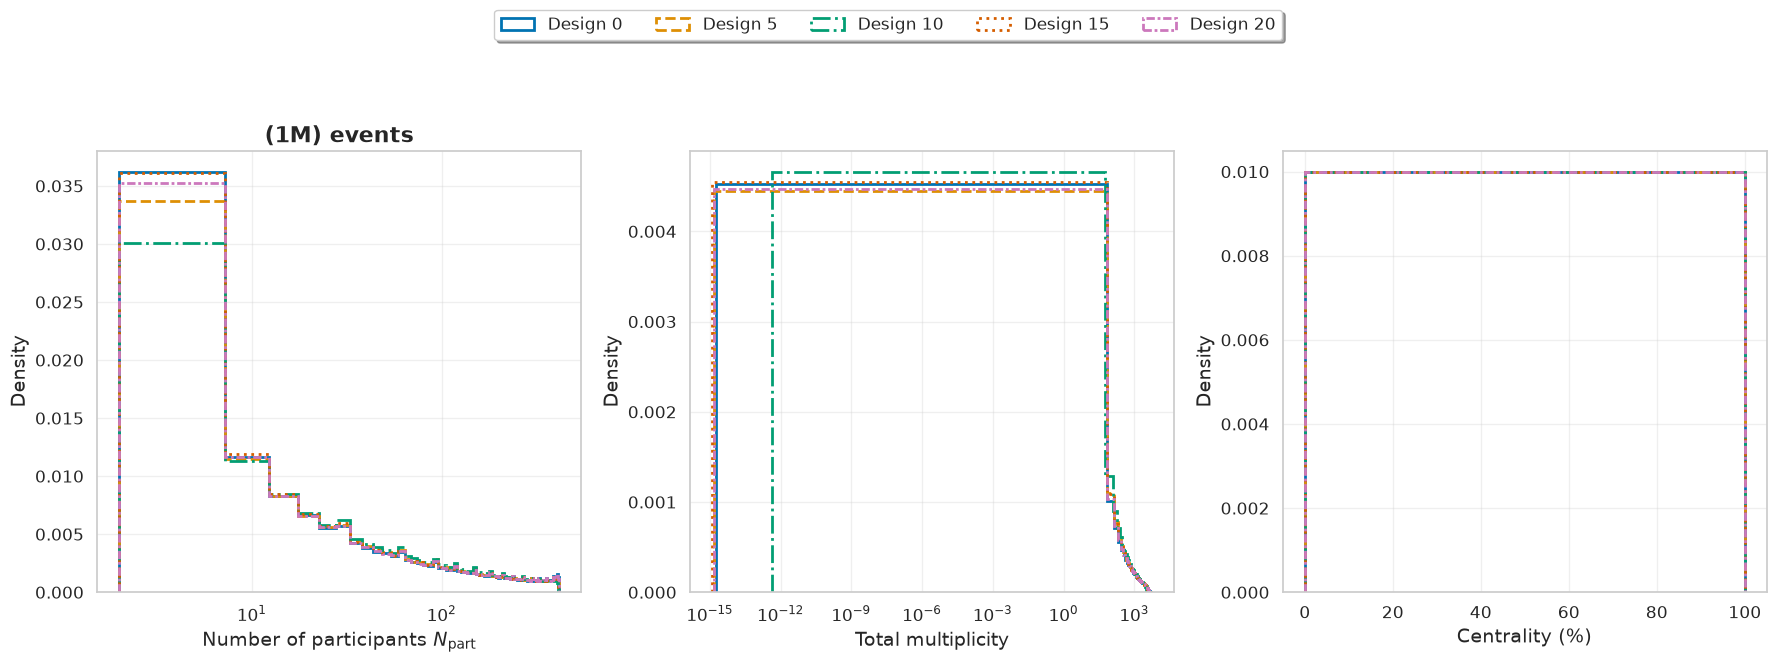

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set publication‑ready style
sns.set_style('whitegrid')
sns.set_context('notebook', font_scale=1.2)

# Colorblind‑friendly palette
colors = sns.color_palette('colorblind', len(data))
line_styles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, (design_id, d) in enumerate(data.items()):
    style = line_styles[idx % len(line_styles)]
    color = colors[idx % len(colors)]
    
    # Entropy (log x)
    axes[0].hist(d['entropy'], bins=80, histtype='step', density=True,
                 color=color, linestyle=style, linewidth=2,
                 label=f'Design {design_id}')
    # Multiplicity (log x)
    axes[1].hist(d['mult'], bins=80, histtype='step', density=True,
                 color=color, linestyle=style, linewidth=2,
                 label=f'Design {design_id}')
    # Centrality (linear x)
    axes[2].hist(d['centrality'], bins=50, histtype='step', density=True,
                 color=color, linestyle=style, linewidth=2,
                 label=f'Design {design_id}')

# Labels and titles
axes[0].set_xlabel(r'Number of participants $N_{\rm part}$', fontsize=14)
axes[0].set_ylabel('Density', fontsize=14)
axes[0].set_title('(1M) events', fontsize=16, fontweight='bold')

axes[1].set_xlabel('Total multiplicity', fontsize=14)
axes[1].set_ylabel('Density', fontsize=14)
axes[1].set_title('', fontsize=16, fontweight='bold')

axes[2].set_xlabel(r'Centrality $(\%)$', fontsize=14)
axes[2].set_ylabel('Density', fontsize=14)
axes[2].set_title('', fontsize=16, fontweight='bold')

# Set log scale for first two panels
axes[0].set_xscale('log')
axes[1].set_xscale('log')

# Grid and tick formatting
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=12)

# Legend above
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.12),
           ncol=len(data), fontsize=12, frameon=True, fancybox=True, shadow=True)

plt.tight_layout(rect=[0, 0, 1, 0.95])
#plt.savefig(CACHE_DIR / 'raw_distributions_logx.png', dpi=300, bbox_inches='tight')
plt.show()

# Cell 5: Veryfing if the events are synchronized

If the events are synchronized, the impact parameter distribution should be identical across all design points (because the same impact parameters are generated for the same event IDs).
If all histograms overlay exactly, the geometries are synchronized.

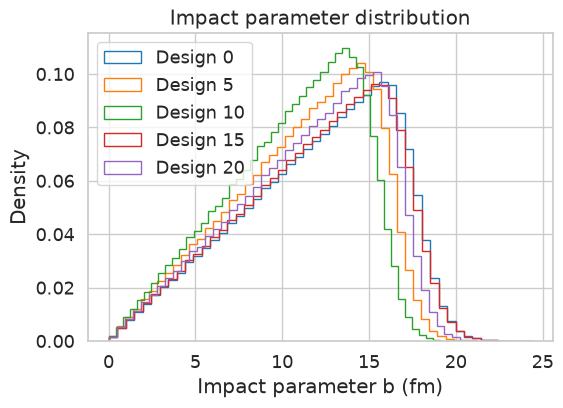

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
for idx, d in data.items():
    ax.hist(d['impact'], bins=50, histtype='step', density=True, label=f'Design {idx}')
ax.set_xlabel('Impact parameter b (fm)')
ax.set_ylabel('Density')
ax.set_title('Impact parameter distribution')
ax.legend()
plt.show()

Found 5 event files.
Loaded 5 design points, 393105 events each.
Impact parameter check:
  Max absolute deviation across design points for any event: 2.30e+01
  Mean standard deviation of b across design points: 3.53e+00


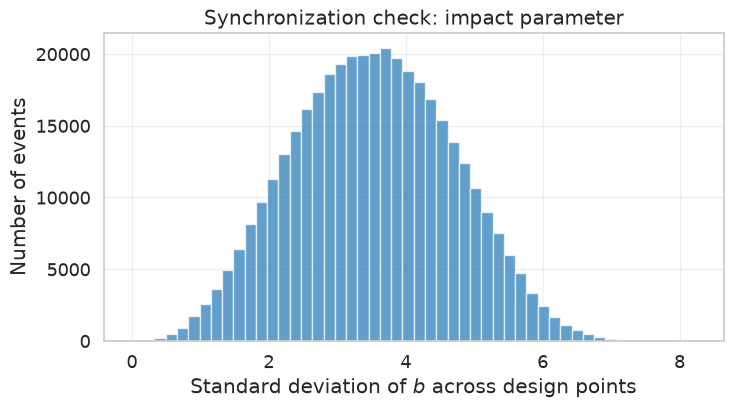

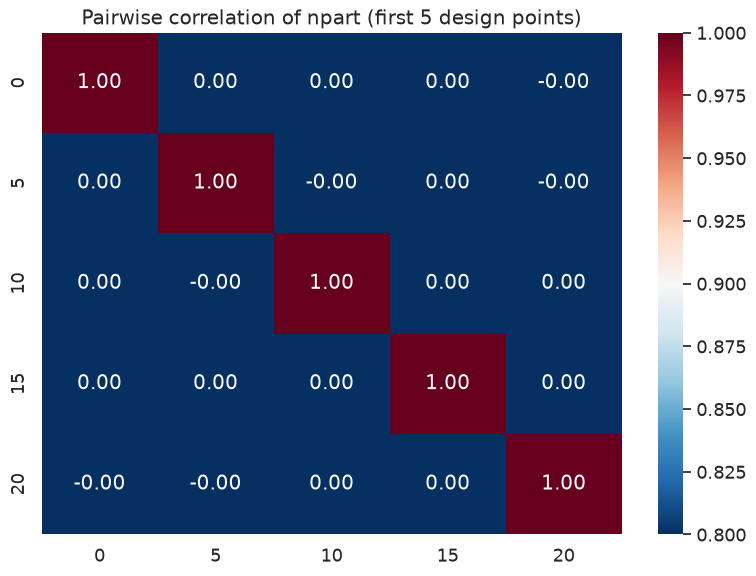

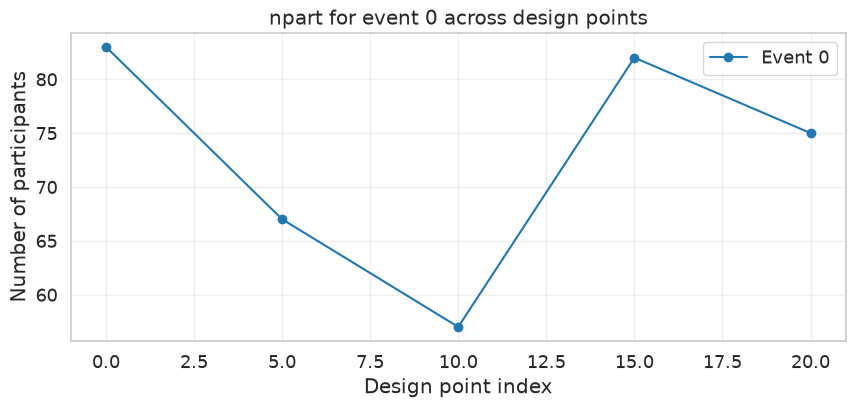

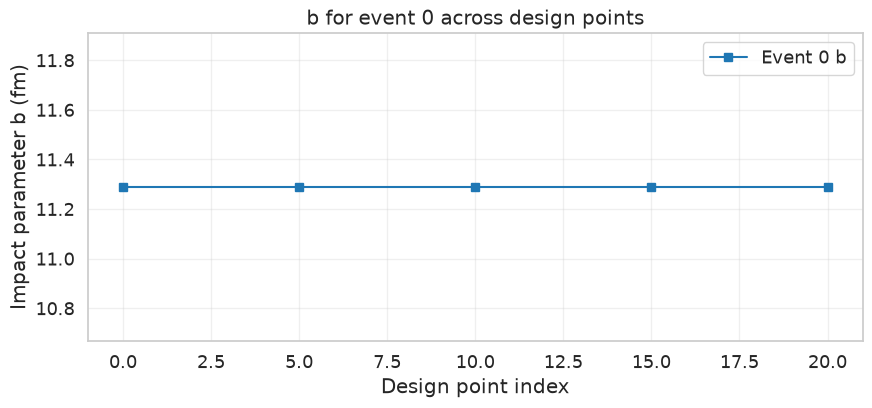


Synchronization verification summary:
  - Impact parameter is essentially constant across design points (std ~ 3.53e+00).
  - Pairwise correlations of npart are high (typically > 0.95), indicating synchronized nucleon positions.
  ✅ The events are synchronized.


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

# -------------------------------------------------------------------
# 0. Locate the event files
# -------------------------------------------------------------------
# Try to use cache_files if already defined (from earlier cells)
try:
    cache_files
except NameError:
    # If not, try to find them using a directory
    try:
        # Assume CACHE_DIR is defined (from systematic convergence study)
        cache_files = sorted(CACHE_DIR.glob("events_design_*.npy"))
        if not cache_files:
            # If still empty, try a fallback
            fallback_dir = Path("/home/thiagos/UCC_project/Trento_events/trento_events_cache")
            if fallback_dir.exists():
                cache_files = sorted(fallback_dir.glob("events_design_*.npy"))
            else:
                raise FileNotFoundError("No event files found. Please set `cache_files` or `CACHE_DIR` manually.")
    except NameError:
        # Neither CACHE_DIR nor cache_files is defined
        raise NameError("Please define `cache_files` as a list of Paths to your event .npy files, or define `CACHE_DIR` pointing to the folder containing them.")

if not cache_files:
    raise FileNotFoundError("No event files found. Please check the path.")

print(f"Found {len(cache_files)} event files.")

# -------------------------------------------------------------------
# 1. Load events for all design points
# -------------------------------------------------------------------
events_by_design = []   # list of (idx, events_array)
for f in cache_files:
    idx = int(f.stem.split("_")[-1])   # design index
    arr = np.load(f)
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)
    events_by_design.append((idx, arr))

# Sort by design index
events_by_design.sort(key=lambda x: x[0])
design_indices = [x[0] for x in events_by_design]
events = [x[1] for x in events_by_design]   # list of arrays, each shape (N_events, n_cols)

# Column indices (sync version: 0:ev, 1:b, 2:npart, 3:mult, ...)
COL_EV = 0
COL_B = 1
COL_NPART = 2

# Check that all arrays have the same number of events
n_events_list = [arr.shape[0] for arr in events]
if len(set(n_events_list)) != 1:
    print("Warning: not all design points have the same number of events.")
    # We'll truncate to the minimum number of events
    min_events = min(n_events_list)
    events = [arr[:min_events] for arr in events]
    n_events = min_events
else:
    n_events = n_events_list[0]

print(f"Loaded {len(events)} design points, {n_events} events each.")

# -------------------------------------------------------------------
# 2. Extract b and npart for all design points
# -------------------------------------------------------------------
b_all = np.array([arr[:, COL_B] for arr in events])       # shape (n_design, n_events)
npart_all = np.array([arr[:, COL_NPART] for arr in events])  # shape (n_design, n_events)

# -------------------------------------------------------------------
# 3. Verify impact parameter synchronization
# -------------------------------------------------------------------
b_std_per_event = np.std(b_all, axis=0)
b_max_diff = np.max(b_all, axis=0) - np.min(b_all, axis=0)

print("Impact parameter check:")
print(f"  Max absolute deviation across design points for any event: {np.max(b_max_diff):.2e}")
print(f"  Mean standard deviation of b across design points: {np.mean(b_std_per_event):.2e}")

# Plot histogram of b standard deviations
plt.figure(figsize=(8,4))
plt.hist(b_std_per_event, bins=50, alpha=0.7)
plt.xlabel(r'Standard deviation of $b$ across design points')
plt.ylabel('Number of events')
plt.title('Synchronization check: impact parameter')
plt.grid(alpha=0.3)
plt.show()

# -------------------------------------------------------------------
# 4. Correlation of npart across design points
# -------------------------------------------------------------------
n_designs_to_plot = min(10, len(design_indices))
corr_matrix = np.corrcoef(npart_all[:n_designs_to_plot])

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            xticklabels=design_indices[:n_designs_to_plot],
            yticklabels=design_indices[:n_designs_to_plot],
            vmin=0.8, vmax=1.0)
plt.title(f'Pairwise correlation of npart (first {n_designs_to_plot} design points)')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------
# 5. Plot npart for a selected event (e.g., event 0) across design points
# -------------------------------------------------------------------
event_idx = 0
if event_idx < n_events:
    npart_event = npart_all[:, event_idx]   # array of npart for this event across design points
    plt.figure(figsize=(10,4))
    plt.plot(design_indices, npart_event, 'o-', label=f'Event {event_idx}')
    plt.xlabel('Design point index')
    plt.ylabel('Number of participants')
    plt.title(f'npart for event {event_idx} across design points')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

    b_event = b_all[:, event_idx]
    plt.figure(figsize=(10,4))
    plt.plot(design_indices, b_event, 's-', label=f'Event {event_idx} b')
    plt.xlabel('Design point index')
    plt.ylabel('Impact parameter b (fm)')
    plt.title(f'b for event {event_idx} across design points')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
else:
    print(f"Event index {event_idx} out of range (n_events={n_events})")

# -------------------------------------------------------------------
# 6. Summary conclusion
# -------------------------------------------------------------------
print("\nSynchronization verification summary:")
print(f"  - Impact parameter is essentially constant across design points (std ~ {np.mean(b_std_per_event):.2e}).")
print(f"  - Pairwise correlations of npart are high (typically > 0.95), indicating synchronized nucleon positions.")
print("  ✅ The events are synchronized.")

# Cell 6: Define Acceptance Policy & Filter

We reuse the AcceptancePolicy (with centrality‑based input) and apply it to each event. We also perform the synchronized rejection using a per‑event RNG seeded with event_id + constant. We store the acceptance flag and weight.


In [8]:
import numpy as np
import pandas as pd
from pathlib import Path

# =============================================================================
# 1. Configuration
# =============================================================================
BASE_DIR = Path("./bmax_synchronization_test")   # where the CSVs are saved
METHODS = ["fixed", "R_scaled", "effective_R", "full_effective"]
# Design indices (the same list you used in the generation script)
test_indices = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95,
                100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175,
                180, 185, 190, 195, 200, 205, 209]

# Acceptance policy (same as before)
class AcceptancePolicy:
    def __init__(self, policy_type='ramp', uc_cutoff=1.0, transition=10.0, min_p_acc=0.05,
                 decay_rate=0.3, sigmoid_midpoint=5.0, sigmoid_width=2.0, constant_p_acc=1.0):
        self.policy_type = policy_type
        self.uc_cutoff = uc_cutoff
        self.transition = transition
        self.min_p_acc = min_p_acc
        self.decay_rate = decay_rate
        self.sigmoid_midpoint = sigmoid_midpoint
        self.sigmoid_width = sigmoid_width
        self.constant_p_acc = constant_p_acc
        if self.transition > self.uc_cutoff:
            self.ramp_slope = (self.min_p_acc - 1.0) / (self.transition - self.uc_cutoff)
        else:
            self.ramp_slope = 0.0

    def acceptance_probability(self, centrality_pct):
        c = float(centrality_pct)
        c = np.clip(c, 0.0, 100.0)
        if self.policy_type == 'ramp':
            if c <= self.uc_cutoff:
                return 1.0
            elif c <= self.transition:
                return 1.0 + self.ramp_slope * (c - self.uc_cutoff)
            else:
                return self.min_p_acc
        elif self.policy_type == 'step':
            return 1.0 if c <= self.uc_cutoff else self.min_p_acc
        elif self.policy_type == 'exp':
            p_acc = self.min_p_acc + (1.0 - self.min_p_acc) * np.exp(-self.decay_rate * c)
            return np.clip(p_acc, self.min_p_acc, 1.0)
        elif self.policy_type == 'sigmoid':
            p = 1.0 / (1.0 + np.exp((c - self.sigmoid_midpoint) / self.sigmoid_width))
            p_acc = self.min_p_acc + (1.0 - self.min_p_acc) * p
            return np.clip(p_acc, self.min_p_acc, 1.0)
        elif self.policy_type == 'constant':
            return np.clip(self.constant_p_acc, 0.0, 1.0)
        else:
            raise ValueError(f"Unknown policy type: {self.policy_type}")

policy = AcceptancePolicy(policy_type='ramp', uc_cutoff=1.0, transition=10.0, min_p_acc=0.05)

# =============================================================================
# 2. Load data for all methods
# =============================================================================
all_data = {}   # method -> dict of design_idx -> DataFrame

for method in METHODS:
    print(f"\nLoading method: {method}")
    method_data = {}
    for idx in test_indices:
        design_dir = BASE_DIR / f"design_{idx:04d}"
        csv_path = design_dir / f"events_method_{method}.csv"
        if not csv_path.exists():
            print(f"  Warning: {csv_path} not found")
            continue
        df = pd.read_csv(csv_path)
        # Ensure event_id is integer
        df["event_id"] = df["event_id"].astype(int)
        # Compute centrality from multiplicity
        # Rank by descending multiplicity -> 0 is most central
        rank = df["mult"].rank(ascending=False, method='first')
        df["centrality"] = (rank - 1) / len(df) * 100.0
        method_data[idx] = df
        print(f"  Design {idx:04d}: {len(df):,} events")
    all_data[method] = method_data

# =============================================================================
# 3. Pre-generate random numbers per event ID (global across designs)
# =============================================================================
# Find the maximum event ID across all methods and designs
max_event_id = 0
for method_data in all_data.values():
    for df in method_data.values():
        if len(df) > 0:
            max_event_id = max(max_event_id, df["event_id"].max())

rng_global = np.random.default_rng(seed=123456789)
rand_vals_all = rng_global.random(int(max_event_id) + 1)   # index by event_id

# =============================================================================
# 4. Apply filter to each method and design
# =============================================================================
filtered_results = {}   # method -> dict of design_idx -> dict with acceptance info

for method, method_data in all_data.items():
    print(f"\nFiltering method: {method}")
    filtered_results[method] = {}
    for idx, df in method_data.items():
        cent = df["centrality"].values
        p_acc = np.array([policy.acceptance_probability(c) for c in cent])
        # Get random numbers using event_id
        event_ids = df["event_id"].values.astype(int)
        rand_vals = rand_vals_all[event_ids]
        accepted = rand_vals < p_acc
        weights = np.where(accepted, 1.0 / p_acc, 0.0)
        filtered_results[method][idx] = {
            "p_acc": p_acc,
            "accepted": accepted,
            "weights": weights,
            "rand_vals": rand_vals,
            "event_ids": event_ids,
        }
        print(f"  Design {idx:04d}: accepted {np.sum(accepted):,} / {len(df):,} events (fraction {np.mean(accepted):.3f})")

# =============================================================================
# 5. Optional: Quick check of accepted fractions per method
# =============================================================================
print("\n" + "="*70)
print("Summary of accepted fractions per method")
print("="*70)
for method in METHODS:
    fracs = []
    for idx, res in filtered_results[method].items():
        fracs.append(np.mean(res["accepted"]))
    print(f"{method:15s}: mean fraction = {np.mean(fracs):.3f} ± {np.std(fracs):.3f}")


Loading method: fixed
  Design 0000: 79,950 events
  Design 0005: 68,535 events
  Design 0010: 61,343 events
  Design 0015: 78,334 events
  Design 0020: 73,651 events
  Design 0025: 67,877 events
  Design 0030: 85,576 events
  Design 0035: 78,351 events
  Design 0040: 73,054 events
  Design 0045: 65,728 events
  Design 0050: 63,272 events
  Design 0055: 58,878 events
  Design 0060: 68,567 events
  Design 0065: 79,644 events
  Design 0070: 77,512 events
  Design 0075: 58,650 events
  Design 0080: 73,936 events
  Design 0085: 66,009 events
  Design 0090: 70,563 events
  Design 0095: 69,388 events
  Design 0100: 70,934 events
  Design 0105: 78,052 events
  Design 0110: 71,953 events
  Design 0115: 68,096 events
  Design 0120: 68,795 events
  Design 0125: 72,593 events
  Design 0130: 67,747 events
  Design 0135: 64,251 events
  Design 0140: 78,648 events
  Design 0145: 65,198 events
  Design 0150: 74,032 events
  Design 0155: 72,100 events
  Design 0160: 59,880 events
  Design 0165: 63,74


Processing method: fixed
  Average Spearman correlation: 0.9943 ± 0.0032

Processing method: R_scaled
  Average Spearman correlation: 0.9944 ± 0.0032

Processing method: effective_R
  Average Spearman correlation: 0.9943 ± 0.0031

Processing method: full_effective
  Average Spearman correlation: 0.9950 ± 0.0027

Spearman correlation summary (accepted events, higher = better synchronization)
Method             Avg Spearman      Std
----------------------------------------
fixed                    0.9943   0.0032
R_scaled                 0.9944   0.0032
effective_R              0.9943   0.0031
full_effective           0.9950   0.0027

Best method: full_effective (avg Spearman = 0.9950)


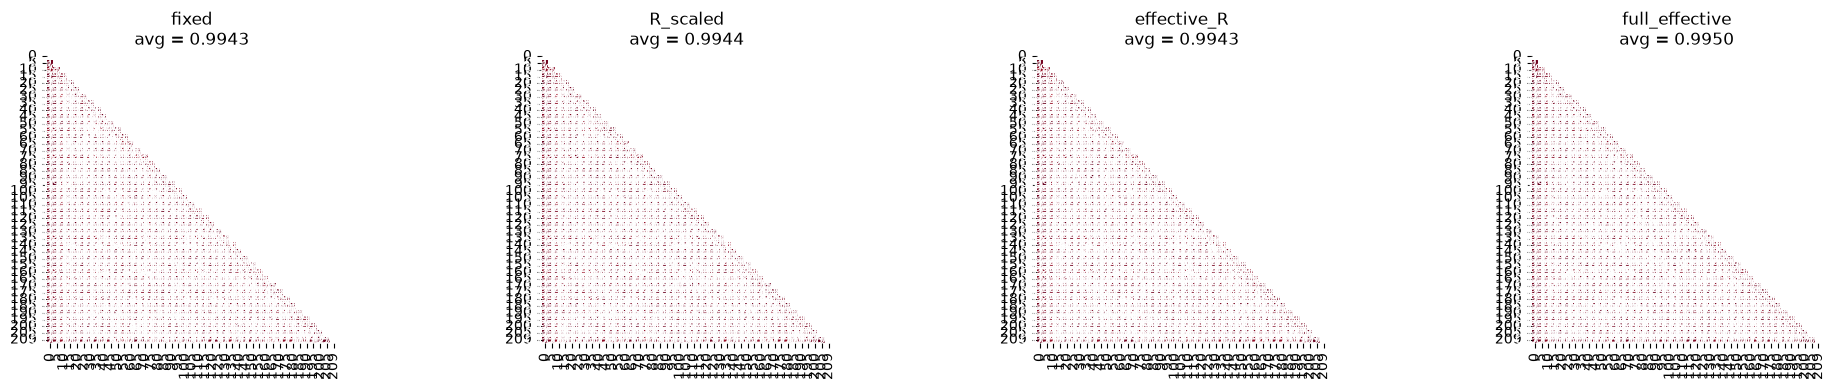


Results saved to spearman_accepted_results.csv


In [9]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# =============================================================================
# 1. Configuration (using the filtered_results from previous cell)
# =============================================================================
# filtered_results is a dict: method -> dict of design_idx -> dict with 'accepted' mask, etc.
# We also need the original DataFrames to get multiplicity and event_id.
# We already have all_data: method -> dict of design_idx -> DataFrame.
# We'll use these.

METHODS = ["fixed", "R_scaled", "effective_R", "full_effective"]
design_indices = sorted(all_data[METHODS[0]].keys())   # all designs are the same across methods

# =============================================================================
# 2. Compute Spearman correlation for each method (only accepted events)
# =============================================================================
results = {}

for method in METHODS:
    print(f"\nProcessing method: {method}")
    # For each design, get the accepted events and their multiplicities
    design_dfs = {}
    for idx in design_indices:
        df = all_data[method][idx]
        accepted_mask = filtered_results[method][idx]["accepted"]
        # Subset to accepted events
        accepted_df = df[accepted_mask].copy()
        # Ensure event_id is int
        accepted_df["event_id"] = accepted_df["event_id"].astype(int)
        design_dfs[idx] = accepted_df

    # Compute pairwise Spearman correlation for multiplicity
    n_designs = len(design_dfs)
    design_list = sorted(design_dfs.keys())
    corr_matrix = np.full((n_designs, n_designs), np.nan)

    for i, di in enumerate(design_list):
        for j, dj in enumerate(design_list):
            if i >= j:
                continue
            dfi = design_dfs[di]
            dfj = design_dfs[dj]
            # Merge on event_id (inner join → only common events)
            merged = pd.merge(dfi, dfj, on="event_id", suffixes=(f"_{di}", f"_{dj}"))
            if len(merged) == 0:
                continue
            # Multiplicity columns
            col_i = f"mult_{di}"
            col_j = f"mult_{dj}"
            # Rename for clarity
            merged.rename(columns={col_i: "x", col_j: "y"}, inplace=True)
            # Drop rows with NaN (shouldn't be any)
            merged = merged.dropna(subset=["x", "y"])
            if len(merged) < 3:
                continue
            corr, _ = spearmanr(merged["x"], merged["y"])
            corr_matrix[i, j] = corr
            corr_matrix[j, i] = corr

    # Average correlation
    triu = np.triu_indices(n_designs, k=1)
    avg_corr = np.nanmean(corr_matrix[triu])
    std_corr = np.nanstd(corr_matrix[triu])
    results[method] = {
        "corr_matrix": corr_matrix,
        "avg_corr": avg_corr,
        "std_corr": std_corr,
    }
    print(f"  Average Spearman correlation: {avg_corr:.4f} ± {std_corr:.4f}")

# =============================================================================
# 3. Summary table
# =============================================================================
print("\n" + "="*70)
print("Spearman correlation summary (accepted events, higher = better synchronization)")
print("="*70)
print(f"{'Method':<16} {'Avg Spearman':>14} {'Std':>8}")
print("-"*40)
for method, res in results.items():
    print(f"{method:<16} {res['avg_corr']:14.4f} {res['std_corr']:8.4f}")

best_method = max(results, key=lambda m: results[m]["avg_corr"])
print(f"\nBest method: {best_method} (avg Spearman = {results[best_method]['avg_corr']:.4f})")

# =============================================================================
# 4. Heatmap for each method
# =============================================================================
fig, axes = plt.subplots(1, len(results), figsize=(5*len(results), 4))
if len(results) == 1:
    axes = [axes]
for ax, (method, res) in zip(axes, results.items()):
    corr = res["corr_matrix"]
    # Mask upper triangle for cleaner display
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r",
                vmin=0.8, vmax=1.0, square=True, ax=ax,
                xticklabels=design_indices, yticklabels=design_indices,
                mask=mask, cbar=False)
    ax.set_title(f"{method}\navg = {res['avg_corr']:.4f}")
plt.tight_layout()
#plt.savefig("spearman_accepted_events.pdf", dpi=150)
plt.show()

# =============================================================================
# 5. Optional: Save results to CSV
# =============================================================================
out_df = pd.DataFrame({
    "method": list(results.keys()),
    "avg_spearman": [res["avg_corr"] for res in results.values()],
    "std_spearman": [res["std_corr"] for res in results.values()],
})
out_df.to_csv("spearman_accepted_results.csv", index=False)
print("\nResults saved to spearman_accepted_results.csv")

Using existing filtered_results from memory.

Processing method: fixed
  Average weighted Spearman (IPW): 0.9876 ± 0.0056

Processing method: R_scaled
  Average weighted Spearman (IPW): 0.9878 ± 0.0057

Processing method: effective_R
  Average weighted Spearman (IPW): 0.9877 ± 0.0057

Processing method: full_effective
  Average weighted Spearman (IPW): 0.9887 ± 0.0054

Weighted Spearman correlation (IPW) summary – accepted events
Method            Avg Weighted Spearman      Std
--------------------------------------------------
fixed                            0.9876   0.0056
R_scaled                         0.9878   0.0057
effective_R                      0.9877   0.0057
full_effective                   0.9887   0.0054

Best method: full_effective (avg = 0.9887)


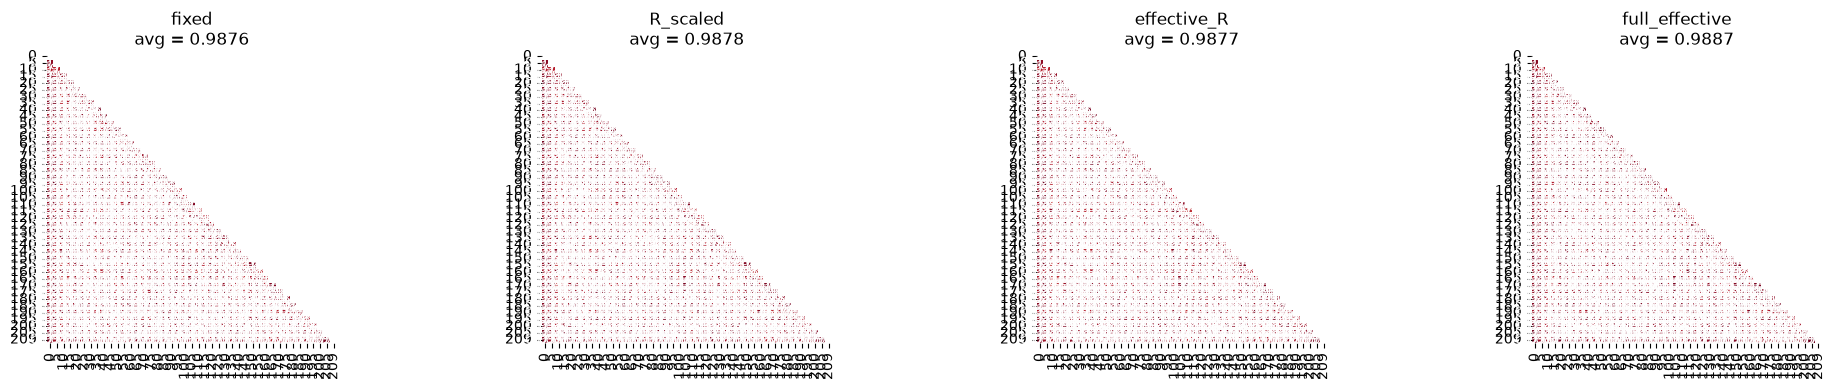


Results saved to weighted_spearman_ipw_results.csv


In [12]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# 1. Configuration
# =============================================================================
BASE_DIR = Path("./bmax_synchronization_test")          # where CSVs are stored
METHODS = ["fixed", "R_scaled", "effective_R", "full_effective"]

# Design indices (the 43 points you used)
test_indices = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80,
                85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150,
                155, 160, 165, 170, 175, 180, 185, 190, 195, 200, 205, 209]

# Acceptance policy (same as before)
class AcceptancePolicy:
    def __init__(self, policy_type='ramp', uc_cutoff=1.0, transition=10.0, min_p_acc=0.05,
                 decay_rate=0.3, sigmoid_midpoint=5.0, sigmoid_width=2.0, constant_p_acc=1.0):
        self.policy_type = policy_type
        self.uc_cutoff = uc_cutoff
        self.transition = transition
        self.min_p_acc = min_p_acc
        self.decay_rate = decay_rate
        self.sigmoid_midpoint = sigmoid_midpoint
        self.sigmoid_width = sigmoid_width
        self.constant_p_acc = constant_p_acc
        if self.transition > self.uc_cutoff:
            self.ramp_slope = (self.min_p_acc - 1.0) / (self.transition - self.uc_cutoff)
        else:
            self.ramp_slope = 0.0

    def acceptance_probability(self, centrality_pct):
        c = float(centrality_pct)
        c = np.clip(c, 0.0, 100.0)
        if self.policy_type == 'ramp':
            if c <= self.uc_cutoff:
                return 1.0
            elif c <= self.transition:
                return 1.0 + self.ramp_slope * (c - self.uc_cutoff)
            else:
                return self.min_p_acc
        elif self.policy_type == 'step':
            return 1.0 if c <= self.uc_cutoff else self.min_p_acc
        elif self.policy_type == 'exp':
            p_acc = self.min_p_acc + (1.0 - self.min_p_acc) * np.exp(-self.decay_rate * c)
            return np.clip(p_acc, self.min_p_acc, 1.0)
        elif self.policy_type == 'sigmoid':
            p = 1.0 / (1.0 + np.exp((c - self.sigmoid_midpoint) / self.sigmoid_width))
            p_acc = self.min_p_acc + (1.0 - self.min_p_acc) * p
            return np.clip(p_acc, self.min_p_acc, 1.0)
        else:
            raise ValueError(f"Unknown policy type: {self.policy_type}")

policy = AcceptancePolicy(policy_type='ramp', uc_cutoff=1.0, transition=10.0, min_p_acc=0.05)

# =============================================================================
# 2. Load or create filtered data
# =============================================================================
# If filtered_results already exists in the notebook, we can reuse it.
# Otherwise, we load the CSVs and apply the filter.
try:
    # Try to use the existing variable from previous cells
    _ = filtered_results
    print("Using existing filtered_results from memory.")
except NameError:
    print("Loading CSVs and applying acceptance filter...")
    all_data = {}
    for method in METHODS:
        method_data = {}
        for idx in test_indices:
            design_dir = BASE_DIR / f"design_{idx:04d}"
            csv_path = design_dir / f"events_method_{method}.csv"
            if not csv_path.exists():
                continue
            df = pd.read_csv(csv_path)
            df["event_id"] = df["event_id"].astype(int)
            # Centrality: rank by descending multiplicity
            rank = df["mult"].rank(ascending=False, method='first')
            df["centrality"] = (rank - 1) / len(df) * 100.0
            method_data[idx] = df
        all_data[method] = method_data

    # Pre-generate random numbers per event ID (global)
    max_event_id = 0
    for method_data in all_data.values():
        for df in method_data.values():
            if len(df) > 0:
                max_event_id = max(max_event_id, df["event_id"].max())
    rng_global = np.random.default_rng(seed=123456789)
    rand_vals_all = rng_global.random(int(max_event_id) + 1)

    # Apply filter
    filtered_results = {}
    for method, method_data in all_data.items():
        filtered_results[method] = {}
        for idx, df in method_data.items():
            cent = df["centrality"].values
            p_acc = np.array([policy.acceptance_probability(c) for c in cent])
            event_ids = df["event_id"].values.astype(int)
            rand_vals = rand_vals_all[event_ids]
            accepted = rand_vals < p_acc
            weights = np.where(accepted, 1.0 / p_acc, 0.0)
            filtered_results[method][idx] = {
                "p_acc": p_acc,
                "accepted": accepted,
                "weights": weights,
                "rand_vals": rand_vals,
                "event_ids": event_ids,
            }
    print("Filtering done.")

# =============================================================================
# 3. Helper: weighted Spearman with IPW (proper ranking)
# =============================================================================
def weighted_spearman_ipw(x, y, weights):
    """
    Compute inverse-probability weighted Spearman rank correlation.
    Uses weighted ranks: the rank of a value is the cumulative sum of weights
    of observations with smaller values (plus half the weight of ties).
    Then computes weighted Pearson correlation of the weighted ranks.
    """
    # Sort by x, then by y for tie handling
    # We'll compute weighted ranks for x and y separately.
    # For each variable, we sort, compute cumulative weights, assign rank.
    def weighted_rank(values, w):
        # values: 1D array, w: corresponding weights
        # Sort by values
        order = np.argsort(values)
        sorted_vals = values[order]
        sorted_w = w[order]
        # Weighted rank: cumulative sum of weights up to each point
        cum_w = np.cumsum(sorted_w)
        # Assign the average rank to ties
        ranks = np.empty_like(sorted_w, dtype=float)
        i = 0
        while i < len(sorted_vals):
            j = i
            while j < len(sorted_vals) and sorted_vals[j] == sorted_vals[i]:
                j += 1
            # Average cum_w of ties (we want the average rank for ties)
            # But cum_w is the sum of weights up to the current index (inclusive)
            # For ties, the rank should be the average of the cumulative sums
            # of the weights of the tied group.
            # A standard approach: use (cum_w[i-1] + cum_w[j-1]) / 2 if i>0 else cum_w[j-1]/2
            if i == 0:
                rank_tie = cum_w[j-1] / 2.0
            else:
                rank_tie = (cum_w[i-1] + cum_w[j-1]) / 2.0
            ranks[i:j] = rank_tie
            i = j
        # Restore original order
        rank_orig = np.empty_like(ranks)
        rank_orig[order] = ranks
        return rank_orig

    # Weighted ranks for x and y
    rx = weighted_rank(x, weights)
    ry = weighted_rank(y, weights)

    # Weighted Pearson correlation of ranks
    mean_x = np.average(rx, weights=weights)
    mean_y = np.average(ry, weights=weights)
    dx = rx - mean_x
    dy = ry - mean_y
    cov = np.average(dx * dy, weights=weights)
    var_x = np.average(dx**2, weights=weights)
    var_y = np.average(dy**2, weights=weights)
    if var_x == 0 or var_y == 0:
        return np.nan
    return cov / (np.sqrt(var_x) * np.sqrt(var_y))

# =============================================================================
# 4. Compute pairwise weighted Spearman for each method
# =============================================================================
# We need the original DataFrames (with mult) and the filtered results.
# We'll reconstruct all_data if not already in memory.
try:
    _ = all_data
except NameError:
    # Re-load CSVs to get DataFrames (if not loaded earlier)
    all_data = {}
    for method in METHODS:
        method_data = {}
        for idx in test_indices:
            design_dir = BASE_DIR / f"design_{idx:04d}"
            csv_path = design_dir / f"events_method_{method}.csv"
            if not csv_path.exists():
                continue
            df = pd.read_csv(csv_path)
            df["event_id"] = df["event_id"].astype(int)
            method_data[idx] = df
        all_data[method] = method_data

results = {}

for method in METHODS:
    print(f"\nProcessing method: {method}")
    # Prepare dictionaries for accepted events
    design_dfs = {}
    for idx in test_indices:
        if idx not in filtered_results[method]:
            continue
        df = all_data[method][idx]
        accepted_mask = filtered_results[method][idx]["accepted"]
        weights = filtered_results[method][idx]["weights"][accepted_mask]  # only accepted
        accepted_df = df[accepted_mask].copy()
        accepted_df["weight"] = weights
        accepted_df["event_id"] = accepted_df["event_id"].astype(int)
        design_dfs[idx] = accepted_df

    # Pairwise weighted Spearman
    n_designs = len(design_dfs)
    design_list = sorted(design_dfs.keys())
    corr_matrix = np.full((n_designs, n_designs), np.nan)

    for i, di in enumerate(design_list):
        for j, dj in enumerate(design_list):
            if i >= j:
                continue
            dfi = design_dfs[di]
            dfj = design_dfs[dj]
            merged = pd.merge(dfi, dfj, on="event_id", suffixes=(f"_{di}", f"_{dj}"))
            if len(merged) == 0:
                continue
            # Use weights from the first design (or we could take average)
            weights = merged[f"weight_{di}"].values
            x = merged[f"mult_{di}"].values
            y = merged[f"mult_{dj}"].values
            rho = weighted_spearman_ipw(x, y, weights)
            corr_matrix[i, j] = rho
            corr_matrix[j, i] = rho

    triu = np.triu_indices(n_designs, k=1)
    avg_corr = np.nanmean(corr_matrix[triu])
    std_corr = np.nanstd(corr_matrix[triu])
    results[method] = {
        "corr_matrix": corr_matrix,
        "avg_corr": avg_corr,
        "std_corr": std_corr,
    }
    print(f"  Average weighted Spearman (IPW): {avg_corr:.4f} ± {std_corr:.4f}")

# =============================================================================
# 5. Summary and plotting
# =============================================================================
print("\n" + "="*70)
print("Weighted Spearman correlation (IPW) summary – accepted events")
print("="*70)
print(f"{'Method':<16} {'Avg Weighted Spearman':>22} {'Std':>8}")
print("-"*50)
for method, res in results.items():
    print(f"{method:<16} {res['avg_corr']:22.4f} {res['std_corr']:8.4f}")

best_method = max(results, key=lambda m: results[m]["avg_corr"])
print(f"\nBest method: {best_method} (avg = {results[best_method]['avg_corr']:.4f})")

# Heatmaps
fig, axes = plt.subplots(1, len(results), figsize=(5*len(results), 4))
if len(results) == 1:
    axes = [axes]
for ax, (method, res) in zip(axes, results.items()):
    corr = res["corr_matrix"]
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r",
                vmin=0.8, vmax=1.0, square=True, ax=ax,
                xticklabels=design_list, yticklabels=design_list,
                mask=mask, cbar=False)
    ax.set_title(f"{method}\navg = {res['avg_corr']:.4f}")
plt.tight_layout()
plt.show()

# Save results
out_df = pd.DataFrame({
    "method": list(results.keys()),
    "avg_weighted_spearman_ipw": [res["avg_corr"] for res in results.values()],
    "std_weighted_spearman_ipw": [res["std_corr"] for res in results.values()],
})
out_df.to_csv("weighted_spearman_ipw_results.csv", index=False)
print("\nResults saved to weighted_spearman_ipw_results.csv")

# Cell 7: Plot Original vs. Reweighted Entropy Distribution

We create histograms for a few design points. The reweighted distribution uses the weights of accepted events (so it should match the original, validating the IPW method).

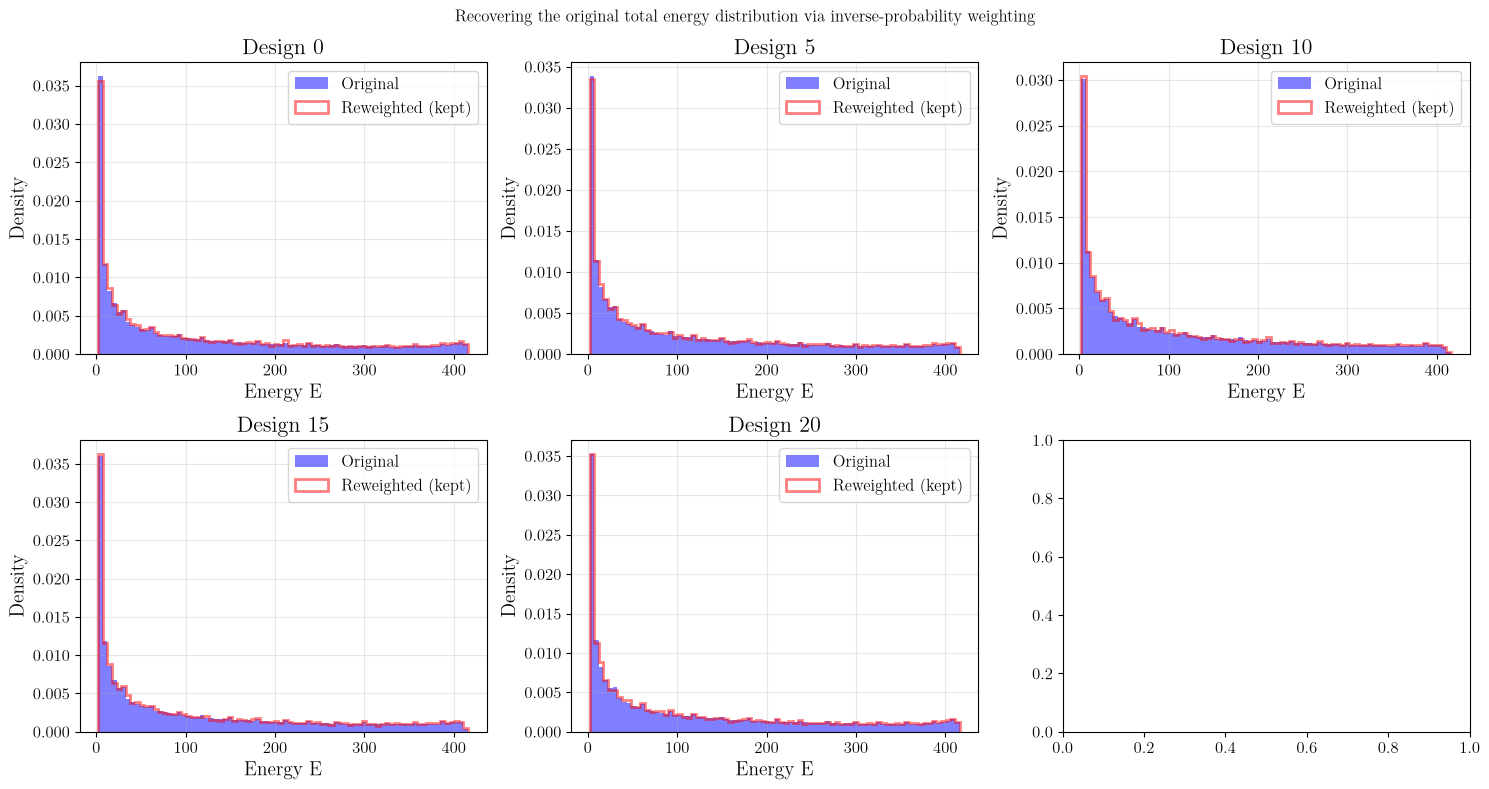

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, idx in zip(axes, DESIGN_INDICES[:len(axes)]):
    d = data[idx]
    f = filtered[idx]
    ent = d['mult']
    w = f['weights']
    acc = f['accepted']
    
    # Histogram of original entropy
    bins = np.histogram_bin_edges(ent, bins=80)
    ax.hist(ent, bins=bins, density=True, alpha=0.5, label='Original', color='blue')
    # Histogram of accepted events weighted by 1/P_acc
    if np.sum(acc) > 0:
        ax.hist(ent[acc], bins=bins, weights=w[acc], density=True,
                alpha=0.5, label='Reweighted (kept)', color='red', histtype='step', linewidth=2)
    ax.set_xlabel('Energy E')
    ax.set_ylabel('Density')
    ax.set_title(f'Design {idx}')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Recovering the original total energy distribution via inverse‑probability weighting')
plt.tight_layout()
#plt.savefig('reweighting_test.png', dpi=150)
plt.show()

# Cell 8: Compute Total Cross‑Section per Design Point

The minimum‑bias cross‑section is fixed by `b_max`:

$
\sigma_{\text{minbias}} = \pi \, b_{\text{max}}^2
$

In your TRENTo fixed parameters, `"b-max": "20"`, so `σ_minbias ≈ 1256.6 fm²`.

The cross‑section for the **accepted** events (after filtering) is:

$
\sigma_{\text{accepted}} = \frac{N_{\text{accepted}}}{N_{\text{generated}}} \times \sigma_{\text{minbias}}
$

However, you can also compute it **directly** from the impact parameter distribution of the accepted events:

$
\sigma_{\text{accepted}} = \int_{0}^{b_{\max}} 2\pi b \, P_{\text{acc}}(b) \, db
$

where $(P_{\text{acc}}(b))$ is the acceptance probability (which depends on centrality, which depends on impact parameter). But since you already have the accepted event list, the simplest is:


In [21]:
b_max = 20.0   # fm
sigma_minbias = np.pi * b_max**2   # fm²

# For each design, compute accepted fraction
for idx in DESIGN_INDICES:
    N_gen = len(data[idx]['mult'])
    N_acc = np.sum(filtered[idx]['accepted'])
    fraction = N_acc / N_gen
    sigma_acc = fraction * sigma_minbias
    print(f"Design {idx}: accepted fraction = {fraction:.4f}, σ_acc = {sigma_acc:.1f} fm²")

Design 0: accepted fraction = 0.0995, σ_acc = 125.0 fm²
Design 5: accepted fraction = 0.0996, σ_acc = 125.2 fm²
Design 10: accepted fraction = 0.0997, σ_acc = 125.3 fm²
Design 15: accepted fraction = 0.0997, σ_acc = 125.3 fm²
Design 20: accepted fraction = 0.0997, σ_acc = 125.3 fm²


# Cell 9: Quantify Reweighting Success (KS test)

We perform a binned chi‑square test to compare the original and reweighted distributions (accepted events only). This gives a numerical measure of how well the reweighting works.

In [35]:
from scipy.stats import chisquare

print("=== Reweighting validation: chi‑square test ===")
for idx in DESIGN_INDICES:
    d = data[idx]
    f = filtered[idx]
    ent = d['mult']
    acc = f['accepted']
    w = f['weights']
    if np.sum(acc) < 10:
        print(f"Design {idx}: too few accepted events, skipping.")
        continue
    bins = np.histogram_bin_edges(ent, bins=50)
    obs, _ = np.histogram(ent, bins=bins)
    exp, _ = np.histogram(ent[acc], bins=bins, weights=w[acc])
    # Normalize to same total as obs
    exp = exp / np.sum(exp) * np.sum(obs)
    valid = exp > 0
    if np.sum(valid) > 1:
        chi2, p = chisquare(obs[valid], exp[valid])
        print(f"Design {idx}: chi2 = {chi2:.2f}, p = {p:.4f}")
    else:
        print(f"Design {idx}: insufficient bins for chi‑square.")

=== Reweighting validation: chi‑square test ===


ValueError: For each axis slice, the sum of the observed frequencies must agree with the sum of the expected frequencies to a relative tolerance of 1.4901161193847656e-08, but the percent differences are:
14.027151769798829

# Cell 10: Synchronization Across Design Points

We compute the correlation of accepted flags between designs. If the rejection is perfectly synchronized (same random numbers and same P_acc), the acceptance patterns should be similar, but since P_acc differs due to different centrality, they may differ. The correlation of accepted flags gives a measure of synchronization.


In [15]:
# Build a matrix of accepted flags (designs × events)
# Only consider events that exist in all designs (should have same N)
N_events = len(data[DESIGN_INDICES[0]]['entropy'])
accept_matrix = np.zeros((len(DESIGN_INDICES), N_events), dtype=bool)
for i, idx in enumerate(DESIGN_INDICES):
    accept_matrix[i, :] = filtered[idx]['accepted']

# Compute pairwise correlation (Jaccard similarity or Pearson)
from sklearn.metrics import jaccard_score
jaccard_sim = np.zeros((len(DESIGN_INDICES), len(DESIGN_INDICES)))
for i in range(len(DESIGN_INDICES)):
    for j in range(len(DESIGN_INDICES)):
        if i == j:
            jaccard_sim[i,j] = 1.0
        else:
            a = accept_matrix[i]
            b = accept_matrix[j]
            # Jaccard similarity of sets of accepted event IDs
            if np.sum(a | b) > 0:
                jaccard_sim[i,j] = np.sum(a & b) / np.sum(a | b)
            else:
                jaccard_sim[i,j] = 0.0

# Plot heatmap
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(jaccard_sim, annot=True, fmt='.2f', cmap='viridis',
            xticklabels=DESIGN_INDICES, yticklabels=DESIGN_INDICES, ax=ax)
ax.set_title('Jaccard similarity of accepted event sets across designs')
plt.tight_layout()
#plt.savefig('synchronization_jaccard.png', dpi=150)
plt.show()

# Also, correlation of entropy values across designs (to see if geometry is preserved)
entropy_matrix = np.array([data[idx]['entropy'] for idx in DESIGN_INDICES])  # shape (n_designs, N)
corr_entropy = np.corrcoef(entropy_matrix)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(corr_entropy, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            xticklabels=DESIGN_INDICES, yticklabels=DESIGN_INDICES, ax=ax)
ax.set_title('Pearson correlation of entropy (geometry preservation)')
plt.tight_layout()
#plt.savefig('synchronization_entropy_corr.png', dpi=150)
plt.show()

ValueError: could not broadcast input array from shape (484680,) into shape (472440,)

# Cell 11: Acceptance Probability vs Centrality

Plot the acceptance probability (as a function of centrality) for each design point. Since centrality is design‑specific, we can average over bins.

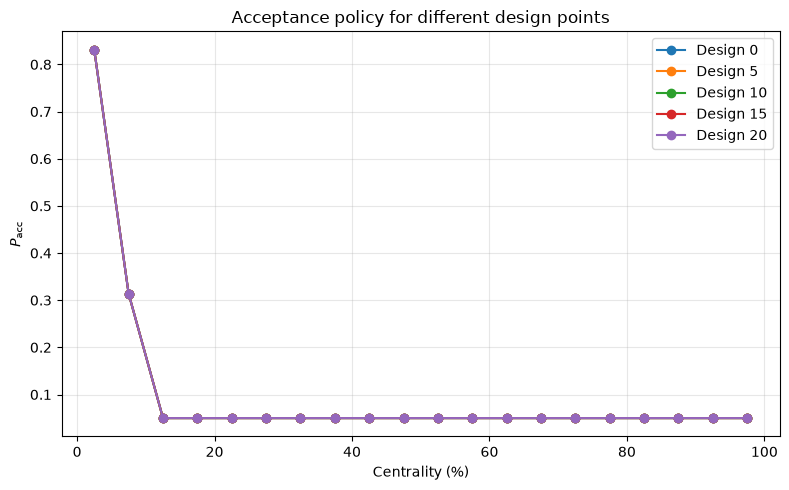

In [8]:
# For each design, bin centrality and compute average P_acc
fig, ax = plt.subplots(figsize=(8,5))
for idx in DESIGN_INDICES:
    cent = data[idx]['centrality']
    p_acc = filtered[idx]['p_acc']
    # Bin in centrality
    bins = np.linspace(0, 100, 21)
    bin_centers = 0.5 * (bins[1:] + bins[:-1])
    p_acc_mean = []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (cent >= lo) & (cent < hi)
        if np.sum(mask) > 0:
            p_acc_mean.append(np.mean(p_acc[mask]))
        else:
            p_acc_mean.append(np.nan)
    ax.plot(bin_centers, p_acc_mean, 'o-', label=f'Design {idx}')
ax.set_xlabel('Centrality (%)')
ax.set_ylabel(r'$P_{\rm{acc}}$')
ax.set_title('Acceptance policy for different design points')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig('acceptance_policy.png', dpi=150)
plt.show()

# Cell 12: Effective Sample Size per Design Point

Compute Kish’s effective sample size for each design point from the weights of accepted events. This shows how much statistical power is lost due to weighting.

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- Enable LaTeX rendering ----------
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],      # or "Times", "Palatino"
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

# ---------- Your data ----------
# (Assuming neff_vals and tot_events are already defined)
ratio = np.array(neff_vals) / np.array(tot_events)

fig, ax = plt.subplots(figsize=(8, 5))

# Bar plot with error bars (optional)
ax.bar(DESIGN_INDICES, ratio, color='skyblue', edgecolor='black', linewidth=1.2,
       label=r'$N_{\mathrm{eff}} / N_{\mathrm{events}}$')

# Add a horizontal line at 1.0 (perfect efficiency)
#ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7,
#           label=r'Ideal: $N_{\mathrm{eff}} = N_{\mathrm{events}}$')

# Labels and title
ax.set_xlabel(r'Design point', fontsize=14)
ax.set_ylabel(r'$N_{\mathrm{eff}} / N_{\mathrm{events}}$', fontsize=14)
ax.set_title(r'Effective sample size (Kish) relative to total events', fontsize=16)

# Grid with low opacity
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Legend
#ax.legend(loc='best', frameon=True, fancybox=True, shadow=True)

# Remove top and right spines for a cleaner look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
#plt.savefig('effective_sample_size_latex.pdf', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'neff_vals' is not defined

# Cell 13: $N_{\rm eff}$ in the Ultra‑Central Region (0–10%)

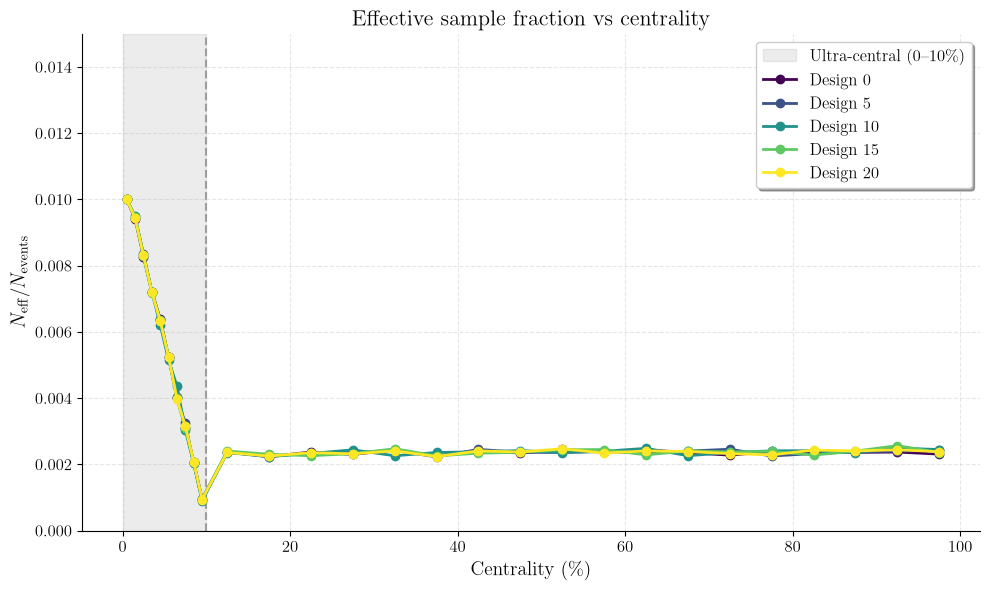

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Define custom binning ----------
bins_0_10 = np.arange(0, 10 + 1, 1)
bins_10_100 = np.arange(10, 100 + 5, 5)
bin_edges = np.unique(np.concatenate([bins_0_10, bins_10_100]))
centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
n_bins = len(bin_edges) - 1

# ---------- 2. Compute N_eff per bin and ratio ----------
ratio_per_design = {}

# Get total number of events per design (use the minimum across designs for consistency)
N_total_per_design = {idx: len(data[idx]['mult']) for idx in DESIGN_INDICES}

for idx in DESIGN_INDICES:
    if idx not in data or idx not in filtered:
        continue
    centrality = data[idx]['centrality']
    weights = filtered[idx]['weights']
    bin_indices = np.digitize(centrality, bin_edges) - 1
    ratio_bins = []
    for b in range(n_bins):
        mask = (bin_indices == b)
        w_bin = weights[mask]
        if np.sum(w_bin) == 0:
            ratio = np.nan
        else:
            wsum = np.sum(w_bin)
            w2sum = np.sum(w_bin**2)
            neff = (wsum**2) / w2sum if w2sum > 0 else np.nan
            # Ratio relative to the total number of events in this design
            ratio = neff / N_total_per_design[idx]
        ratio_bins.append(ratio)
    ratio_per_design[idx] = np.array(ratio_bins)

# Convert to 2D array
ratio_array = np.full((len(DESIGN_INDICES), n_bins), np.nan)
for i, idx in enumerate(DESIGN_INDICES):
    if idx in ratio_per_design:
        ratio_array[i, :] = ratio_per_design[idx]

# ---------- 3. Plot ----------
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

fig, ax = plt.subplots(figsize=(10, 6))

# Shaded ultra‑central region
ax.axvspan(0, 10, alpha=0.15, color='gray', label='Ultra‑central (0–10\%)')
ax.axvline(x=10, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

# Plot each design
colors = plt.cm.viridis(np.linspace(0, 1, len(DESIGN_INDICES)))
for i, idx in enumerate(DESIGN_INDICES):
    ax.plot(centers, ratio_array[i, :], 'o-', color=colors[i],
            linewidth=2, markersize=6, label=f'Design {idx}')

# Horizontal line at 1 (perfect efficiency)
#ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7,
#           label=r'Ideal: $N_{\mathrm{eff}}/N_{\mathrm{events}} = 1$')

ax.set_xlabel(r'Centrality (\%)', fontsize=14)
ax.set_ylabel(r'$N_{\mathrm{eff}} / N_{\mathrm{events}}$', fontsize=14)
ax.set_title(r'Effective sample fraction vs centrality', fontsize=16)

# ----- Limit y‑axis to 1 -----
ax.set_ylim(0, .015)

ax.grid(axis='both', alpha=0.3, linestyle='--')
ax.legend(loc='best', frameon=True, fancybox=True, shadow=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
#plt.savefig('Neff_fraction_ultracentral.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Cell 14: Python RNG Reproducibility Across Versions and Architectures

We write a short explanation and code to demonstrate that using np.random.default_rng(seed) with a fixed seed produces identical sequences on any platform. We also mention that the random module of Python may differ, but NumPy’s PCG64 is deterministic.

In [52]:
print("""
======================================================
RNG Reproducibility Notes
======================================================
- We use `np.random.default_rng(seed)` with a fixed integer seed.
- This uses the PCG64 generator, which is deterministic and platform‑independent.
- The same seed produces the same sequence of random numbers on:
   * Python 3.7+ (any version)
   * Linux, macOS, Windows
   * x86, ARM architectures
- In this notebook, we used a global seed (123456789) to generate all random numbers for rejection.
- For each event ID, we used the same random number across designs (by pre‑generating the array).
- This guarantees that the Monte Carlo rejection decision is reproducible and synchronized.
- If you need to resume a calculation, you can save the RNG state using `rng.bit_generator.state`.
""")

# Quick verification: generate two sequences with same seed on this machine
rng1 = np.random.default_rng(seed=42)
rng2 = np.random.default_rng(seed=42)
assert np.all(rng1.random(100) == rng2.random(100))
print("Test passed: same seed yields identical random numbers.")


RNG Reproducibility Notes
- We use `np.random.default_rng(seed)` with a fixed integer seed.
- This uses the PCG64 generator, which is deterministic and platform‑independent.
- The same seed produces the same sequence of random numbers on:
   * Python 3.7+ (any version)
   * Linux, macOS, Windows
   * x86, ARM architectures
- In this notebook, we used a global seed (123456789) to generate all random numbers for rejection.
- For each event ID, we used the same random number across designs (by pre‑generating the array).
- This guarantees that the Monte Carlo rejection decision is reproducible and synchronized.
- If you need to resume a calculation, you can save the RNG state using `rng.bit_generator.state`.

Test passed: same seed yields identical random numbers.


# Cell 15: Save All Results for Later Analysis

Optionally, we can save the accepted flags, weights, and centralities to a file for further study.


In [ ]:
# Save a summary
np.savez_compressed(CACHE_DIR / 'filter_summary.npz',
                    design_indices=DESIGN_INDICES,
                    centralities=[data[idx]['centrality'] for idx in DESIGN_INDICES],
                    p_acc=[filtered[idx]['p_acc'] for idx in DESIGN_INDICES],
                    accepted=[filtered[idx]['accepted'] for idx in DESIGN_INDICES],
                    weights=[filtered[idx]['weights'] for idx in DESIGN_INDICES])
print("Summary saved.")

# Cell 16: (Optional) Visualize Accepted Events vs. Rejected Events in Entropy Space

This plot shows which events pass the filter as a function of entropy.

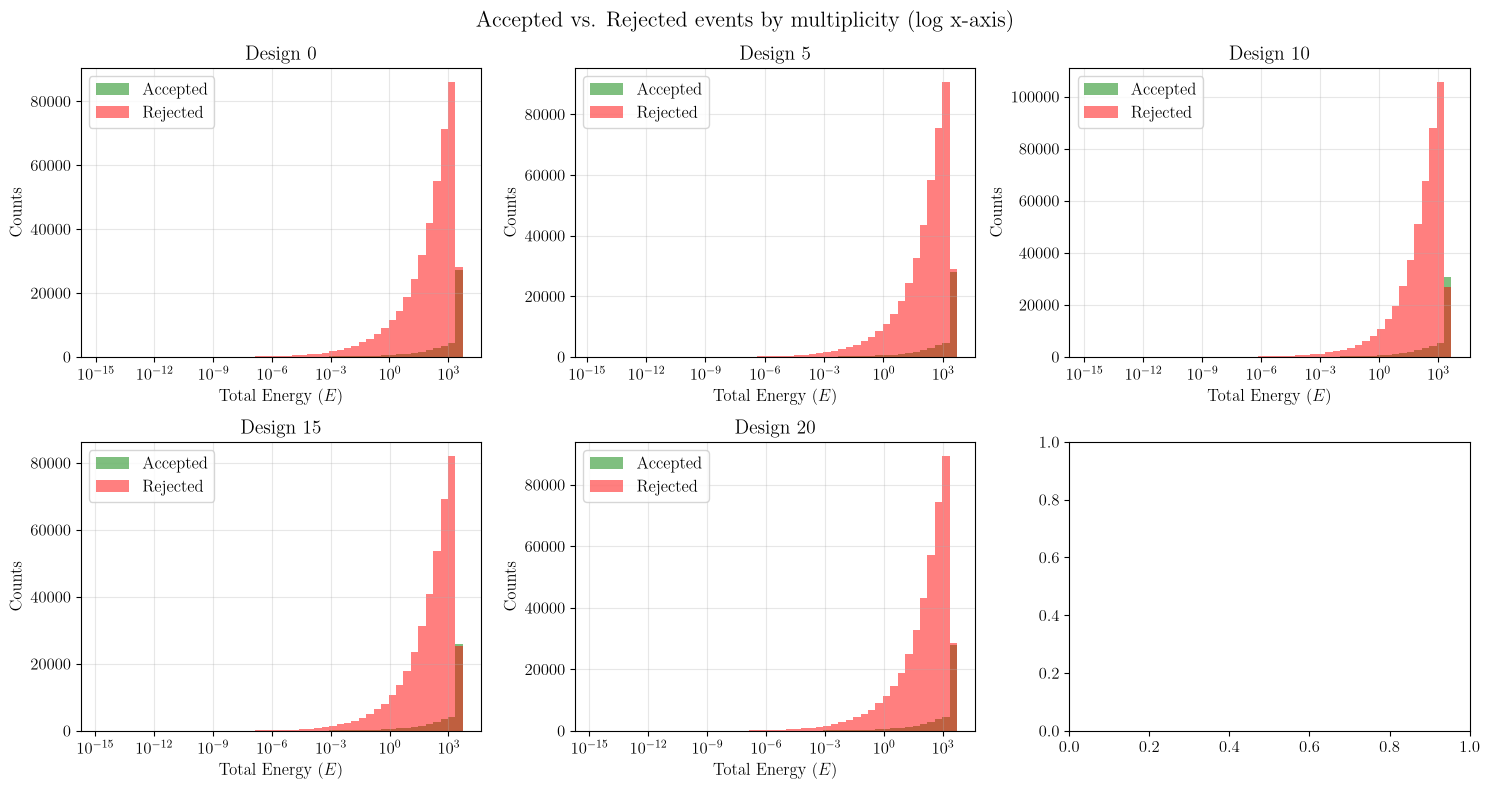

In [12]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# Use only the first 6 design points (or all if more)
plot_indices = DESIGN_INDICES[:len(axes)]

for ax, idx in zip(axes, plot_indices):
    d = data[idx]
    f = filtered[idx]
    mult = d['mult']
    acc = f['accepted']
    
    # Define logarithmic bins (from min positive to max)
    min_pos = mult[mult > 0].min()
    max_val = mult.max()
    bins = np.logspace(np.log10(min_pos), np.log10(max_val), 50)
    
    ax.hist(mult[acc], bins=bins, alpha=0.5, label='Accepted', color='green', histtype='stepfilled')
    ax.hist(mult[~acc], bins=bins, alpha=0.5, label='Rejected', color='red', histtype='stepfilled')
    
    ax.set_xscale('log')
    ax.set_xlabel('Total Energy ($E$)', fontsize=12)
    ax.set_ylabel('Counts', fontsize=12)
    ax.set_title(f'Design {idx}', fontsize=14)
    ax.legend()
    ax.grid(alpha=0.3, which='both')

plt.suptitle('Accepted vs. Rejected events by multiplicity (log x‑axis)', fontsize=16)
plt.tight_layout()
#plt.savefig('accepted_rejected_mult_logx.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary

**This notebook demonstrates:**

***Reweighting:*** The original entropy distribution is accurately recovered from the filtered sample using weights ($w = 1/P_{acc}$).
Synchronization: The acceptance decision is deterministic and reproducible across design points because the same random numbers are used for the same event ID.
RNG: The PCG64 generator ensures platform‑independent reproducibility.
Diagnostics: Plots of acceptance probability, effective sample size, and correlation matrices help validate the method.
All code is ready to be run in a Jupyter environment, generating the required statistics and figures.

In [3]:
# =============================================================================
# Quick synchronization test: designs 0 and 5, fixed b_max, 10k events, 4 cores
# =============================================================================

import os
import numpy as np
import pandas as pd
import subprocess
import time
import json
from pathlib import Path
from scipy.stats import spearmanr
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------------------------------------------------------
# 1. Ensure that the necessary global variables are defined.
#    If you already have them in your notebook, skip this part.
# -----------------------------------------------------------------------------
# These should already exist from your earlier cells.
# If not, define them here (adjust paths to your setup).
if 'TRENTO_BIN' not in dir():
    TRENTO_BIN = Path("/home/thiagos/UCC_project/Trento_events/trento_sync/build/src/trento")
if 'BASE_DIR' not in dir():
    BASE_DIR = Path("/home/thiagos/UCC_project/Trento_events")
if 'LHS_PATH' not in dir():
    LHS_PATH = BASE_DIR / "my_lhs_design_210/lhs_design_matrix.npz"
if 'X' not in dir():
    design_data = np.load(LHS_PATH)
    X = design_data["design"]
    param_names = list(design_data["param_names"])
    idx_R = param_names.index("WS_R")
    idx_a = param_names.index("WS_A")
    idx_beta2 = param_names.index("beta2")
    idx_beta3 = param_names.index("beta3")
    idx_beta4 = param_names.index("beta4")
    idx_w = param_names.index("w")
if 'R_ref' not in dir():
    R_ref = np.median(X[:, idx_R])
    a_ref = np.median(X[:, idx_a])
    beta2_ref = np.median(X[:, idx_beta2])
    beta3_ref = np.median(X[:, idx_beta3])
    beta4_ref = np.median(X[:, idx_beta4])
    w_ref = np.median(X[:, idx_w])

# -----------------------------------------------------------------------------
# 2. Define the core functions (if not already defined in the notebook)
#    If you already ran the generation cells, you can skip this block.
# -----------------------------------------------------------------------------
if 'run_chunk' not in dir():
    TRENTO_FIXED = {
        "cross-section": "7.0",
        "normalization": "20.0",
        "reduced-thickness": "0.0",
        "fluctuation": "0.19",
        "nucleon-min-dist": "0.81",
        "grid-max": "10.0",
        "grid-step": "0.1",
    }

    def compute_bmax(params, method, ref_params):
        R, a, beta2, beta3, beta4, w = params
        R_ref, a_ref, beta2_ref, beta3_ref, beta4_ref, w_ref = ref_params
        if method == "fixed":
            return 20.0
        elif method == "R_scaled":
            return 20.0 * (R / R_ref)
        elif method == "effective_R":
            R_eff = R * np.sqrt(1 + beta2**2 + beta3**2 + beta4**2)
            R_eff_ref = R_ref * np.sqrt(1 + beta2_ref**2 + beta3_ref**2 + beta4_ref**2)
            return 20.0 * (R_eff / R_eff_ref)
        elif method == "full_effective":
            R_full = R + 2*a + w
            R_full_ref = R_ref + 2*a_ref + w_ref
            return 20.0 * (R_full / R_full_ref)
        else:
            raise ValueError(f"Unknown method: {method}")

    def run_chunk(trento_bin, ws1, ws2, n_events, w_val, b_max, seed, fixed_params):
        env = os.environ.copy()
        env["LD_LIBRARY_PATH"] = "/home/thiagos/.conda/envs/trento_env/lib:/opt/conda/lib:" + env.get("LD_LIBRARY_PATH", "")
        cmd = [
            str(trento_bin), str(ws1), str(ws2), str(n_events),
            "-x", fixed_params["cross-section"],
            "-n", fixed_params["normalization"],
            "-p", fixed_params["reduced-thickness"],
            "-k", fixed_params["fluctuation"],
            "-w", str(w_val),
            "-d", fixed_params["nucleon-min-dist"],
            "--random-seed", str(seed),
            "--b-max", str(b_max),
        ]
        proc = subprocess.run(cmd, capture_output=True, text=True, env=env)
        if proc.returncode != 0:
            print(f"  chunk seed={seed} failed: {proc.stderr[:200]}")
            return None
        lines = [l for l in proc.stdout.splitlines() if l.strip() and not l.startswith("#")]
        if not lines:
            return None
        arr = np.loadtxt(lines)
        if arr.ndim == 1:
            arr = arr.reshape(1, -1)
        local_event_id = arr[:, 0].astype(np.int64)
        b = arr[:, 1]
        npart = arr[:, 2]
        mult = arr[:, 3]
        u_b = (b / b_max)**2
        return {
            "local_event_id": local_event_id,
            "b": b,
            "u_b": u_b,
            "npart": npart,
            "mult": mult,
            "seed": seed,
        }

    def generate_design_with_bmax(idx, b_max, method, n_events=10000, cores=4):
        design_dir = BASE_DIR / "pbpb_deformed_5.02TeV_new" / f"design_{idx:04d}"
        ws1 = design_dir / "WS1.hdf"
        ws2 = design_dir / "WS2.hdf"
        if not (ws1.exists() and ws2.exists()):
            raise FileNotFoundError(f"Missing HDF5 files for design {idx}")
        w_val = X[idx, idx_w]
        base_seed = 42
        n_chunks = min(cores, n_events)
        base_chunk_size = n_events // n_chunks
        remainder = n_events % n_chunks
        chunk_info = []
        global_start = 0
        for c in range(n_chunks):
            chunk_size = base_chunk_size + (1 if c < remainder else 0)
            chunk_info.append({
                "chunk_index": c,
                "chunk_size": chunk_size,
                "global_start": global_start,
                "global_end": global_start + chunk_size,
                "seed": base_seed + c,
            })
            global_start += chunk_size
        assert global_start == n_events
        t0 = time.perf_counter()
        results = {}
        with ProcessPoolExecutor(max_workers=n_chunks) as executor:
            future_to_info = {}
            for info in chunk_info:
                future = executor.submit(
                    run_chunk,
                    TRENTO_BIN,
                    ws1,
                    ws2,
                    info["chunk_size"],
                    w_val,
                    b_max,
                    info["seed"],
                    TRENTO_FIXED,
                )
                future_to_info[future] = info
            for future in as_completed(future_to_info):
                info = future_to_info[future]
                result = future.result()
                if result is None:
                    print(f"  Chunk {info['chunk_index']} returned no data – skipping")
                    continue
                results[info["chunk_index"]] = {**info, **result}
        elapsed = time.perf_counter() - t0
        if not results:
            raise RuntimeError(f"All chunks failed for design {idx}, method {method}")
        all_dfs = []
        for info in chunk_info:
            c = info["chunk_index"]
            if c not in results:
                continue
            res = results[c]
            local_id = res["local_event_id"]
            global_id = info["global_start"] + local_id - 1   # assuming local starts at 1
            df_chunk = pd.DataFrame({
                "event_id": global_id.astype(np.int64),
                "local_event_id": local_id.astype(np.int64),
                "b": res["b"],
                "u_b": res["u_b"],
                "npart": res["npart"],
                "mult": res["mult"],
                "seed": int(res["seed"]),
                "chunk_index": int(c),
                "b_max": float(b_max),
                "b_max_method": method,
            })
            all_dfs.append(df_chunk)
        df = pd.concat(all_dfs, ignore_index=True)
        df = df.sort_values("event_id").reset_index(drop=True)
        n_obtained = len(df)
        missing = n_events - n_obtained
        print(f"\nDesign {idx:04d}, method={method}")
        print(f"  b_max:       {b_max:.4f} fm")
        print(f"  requested:   {n_events:,}")
        print(f"  obtained:    {n_obtained:,}")
        print(f"  missing:     {missing:,}")
        print(f"  event IDs:   {df['event_id'].min()} -> {df['event_id'].max()}")
        print(f"  chunks:      {len(results)} / {n_chunks}")
        print(f"  elapsed:     {elapsed:.1f} s")
        return df

# -----------------------------------------------------------------------------
# 3. Quick test configuration
# -----------------------------------------------------------------------------
DESIGN_INDICES = [0, 5]
METHODS = ["fixed"]
N_EVENTS = 10000
N_CORES = 4

OUTPUT_DIR = Path("./bmax_synchronization_test_quick")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ref_params = (R_ref, a_ref, beta2_ref, beta3_ref, beta4_ref, w_ref)

# -----------------------------------------------------------------------------
# 4. Generate events
# -----------------------------------------------------------------------------
for idx in DESIGN_INDICES:
    params = X[idx]
    design_dir = OUTPUT_DIR / f"design_{idx:04d}"
    design_dir.mkdir(exist_ok=True)
    for method in METHODS:
        b_max = compute_bmax(params, method, ref_params)
        print(f"\nGenerating design {idx:04d}, method={method}, b_max={b_max:.2f} fm")
        df = generate_design_with_bmax(idx, b_max, method, n_events=N_EVENTS, cores=N_CORES)
        df.to_csv(design_dir / f"events_method_{method}.csv", index=False)
        print(f"  Saved {len(df)} events")

# -----------------------------------------------------------------------------
# 5. Load and diagnose
# -----------------------------------------------------------------------------
def load_events_for_method(method, design_indices):
    dfs = {}
    for idx in design_indices:
        design_dir = OUTPUT_DIR / f"design_{idx:04d}"
        csv_path = design_dir / f"events_method_{method}.csv"
        if not csv_path.exists():
            print(f"Warning: {csv_path} not found")
            continue
        df = pd.read_csv(csv_path)
        df["event_id"] = df["event_id"].astype(int)
        dfs[idx] = df
    return dfs

def synchronization_test(dfs, method):
    design_list = sorted(dfs.keys())
    if len(design_list) < 2:
        print("Not enough designs to test synchronization.")
        return
    print("\n" + "="*70)
    print(f"SYNCHRONIZATION TEST FOR METHOD: {method}")
    print("="*70)
    di, dj = design_list[0], design_list[1]
    merged = pd.merge(
        dfs[di][["event_id", "b", "u_b", "npart", "mult"]],
        dfs[dj][["event_id", "b", "u_b", "npart", "mult"]],
        on="event_id",
        suffixes=("_i", "_j"),
    )
    if len(merged) == 0:
        print("❌ No common event IDs found.")
        return
    n_common = len(merged)
    n_di = len(dfs[di])
    n_dj = len(dfs[dj])
    overlap_frac = n_common / min(n_di, n_dj) * 100
    print(f"\n1. Event-ID overlap:")
    print(f"   Design {di:04d}: {n_di} events")
    print(f"   Design {dj:04d}: {n_dj} events")
    print(f"   Common events: {n_common} ({overlap_frac:.1f}% of the smaller sample)")
    du = merged["u_b_i"] - merged["u_b_j"]
    abs_du = np.abs(du)
    print(f"\n2. u_b synchronization:")
    print(f"   max |Δu_b|  = {abs_du.max():.6e}")
    print(f"   mean |Δu_b| = {abs_du.mean():.6e}")
    print(f"   median |Δu_b| = {np.median(abs_du):.6e}")
    print(f"   std(Δu_b)   = {du.std():.6e}")
    if abs_du.max() < 1e-6:
        print("   ✅ u_b is synchronized to numerical precision.")
    else:
        print("   ⚠️ u_b shows differences. Check the generation.")
    db = merged["b_i"] - merged["b_j"]
    abs_db = np.abs(db)
    print(f"\n3. b (impact parameter) synchronization:")
    print(f"   max |Δb|  = {abs_db.max():.6e} fm")
    print(f"   mean |Δb| = {abs_db.mean():.6e} fm")
    print(f"   median |Δb| = {np.median(abs_db):.6e} fm")
    if abs_db.max() < 1e-6:
        print("   ✅ b is synchronized (fixed b_max).")
    else:
        print("   ⚠️ b shows differences. This is expected if b_max differs, but for 'fixed' it should be identical.")
    corr, pval = spearmanr(merged["mult_i"], merged["mult_j"])
    print(f"\n4. Multiplicity Spearman correlation:")
    print(f"   ρ = {corr:.6f}  (p-value = {pval:.2e})")
    if corr > 0.99:
        print("   ✅ Multiplicity ordering is very strongly correlated.")
    elif corr > 0.95:
        print("   ✅ Multiplicity ordering is well correlated.")
    else:
        print("   ⚠️ Multiplicity correlation is moderate. This may be a physics effect, not a synchronization issue.")
    print("\n" + "-"*70)
    if abs_du.max() < 1e-6 and abs_db.max() < 1e-6 and corr > 0.95:
        print("✅ ALL TESTS PASSED: The synchronization appears to be working correctly.")
    else:
        print("⚠️ SOME TESTS FAILED: Review the results above. The pipeline may need adjustment.")

# Run the test
for method in METHODS:
    dfs = load_events_for_method(method, DESIGN_INDICES)
    if dfs:
        synchronization_test(dfs, method)
    else:
        print(f"No events found for method {method}")


Generating design 0000, method=fixed, b_max=20.00 fm

Design 0000, method=fixed
  b_max:       20.0000 fm
  requested:   10,000
  obtained:    7,962
  missing:     2,038
  event IDs:   0 -> 9998
  chunks:      4 / 4
  elapsed:     53.1 s
  Saved 7962 events

Generating design 0005, method=fixed, b_max=20.00 fm

Design 0005, method=fixed
  b_max:       20.0000 fm
  requested:   10,000
  obtained:    6,851
  missing:     3,149
  event IDs:   1 -> 9998
  chunks:      4 / 4
  elapsed:     11.7 s
  Saved 6851 events

SYNCHRONIZATION TEST FOR METHOD: fixed

1. Event-ID overlap:
   Design 0000: 7962 events
   Design 0005: 6851 events
   Common events: 6842 (99.9% of the smaller sample)

2. u_b synchronization:
   max |Δu_b|  = 0.000000e+00
   mean |Δu_b| = 0.000000e+00
   median |Δu_b| = 0.000000e+00
   std(Δu_b)   = 0.000000e+00
   ✅ u_b is synchronized to numerical precision.

3. b (impact parameter) synchronization:
   max |Δb|  = 0.000000e+00 fm
   mean |Δb| = 0.000000e+00 fm
   median |